# Film Similarity and Clustering

Loads the processed feature outputs from the previous stage and uses them to:

- compute similarity between films
- test clustering solutions
- evaluate cluster quality
- interpret the resulting clusters
- visualize the film space in two dimensions

The goal is not only to produce clusters, but to identify groups that are coherent and interpretable.

In [1]:
from pathlib import Path
from collections import Counter

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap.umap_ as umap

from scipy.sparse import hstack, load_npz
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

c:\Users\Georg\miniconda3\envs\fataEnv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the saved outputs

We load the processed dataframe, the fitted transformers, and the saved feature matrices from the previous notebook.

In [2]:
PROJECT_ROOT = Path.cwd().parents[1]

OUTPUTS_DIR = PROJECT_ROOT / "outputs" / "text_clustering"
FEATURES_DIR = OUTPUTS_DIR / "features"
RESULTS_DIR = OUTPUTS_DIR / "results"

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

PROCESSED_PATH = FEATURES_DIR / "processed_films.csv"

TFIDF_VECTORIZER_PATH = FEATURES_DIR / "tfidf_vectorizer.joblib"
GENRE_MLB_PATH = FEATURES_DIR / "genre_mlb.joblib"
KEYWORD_MLB_PATH = FEATURES_DIR / "keyword_mlb.joblib"
METADATA_OHE_PATH = FEATURES_DIR / "metadata_ohe.joblib"

X_PLOT_TFIDF_PATH = FEATURES_DIR / "X_plot_tfidf.npz"
X_GENRES_PATH = FEATURES_DIR / "X_genres.npz"
X_KEYWORDS_PATH = FEATURES_DIR / "X_keywords.npz"
X_METADATA_PATH = FEATURES_DIR / "X_metadata.npz"
X_PLOT_ONLY_PATH = FEATURES_DIR / "X_plot_only.npz"
X_FULL_BASELINE_PATH = FEATURES_DIR / "X_full_baseline.npz"

In [3]:
df = pd.read_csv(PROCESSED_PATH)

tfidf_vectorizer = joblib.load(TFIDF_VECTORIZER_PATH)
genre_mlb = joblib.load(GENRE_MLB_PATH)
keyword_mlb = joblib.load(KEYWORD_MLB_PATH)
metadata_ohe = joblib.load(METADATA_OHE_PATH)

X_plot_tfidf = load_npz(X_PLOT_TFIDF_PATH)
X_genres = load_npz(X_GENRES_PATH)
X_keywords = load_npz(X_KEYWORDS_PATH)
X_metadata = load_npz(X_METADATA_PATH)
X_plot_only = load_npz(X_PLOT_ONLY_PATH)
X_full_baseline = load_npz(X_FULL_BASELINE_PATH)

print("DataFrame shape:", df.shape)
print("X_plot_tfidf:", X_plot_tfidf.shape)
print("X_genres:", X_genres.shape)
print("X_keywords:", X_keywords.shape)
print("X_metadata:", X_metadata.shape)
print("X_plot_only:", X_plot_only.shape)
print("X_full_baseline:", X_full_baseline.shape)

DataFrame shape: (2000, 15)
X_plot_tfidf: (2000, 3946)
X_genres: (2000, 24)
X_keywords: (2000, 9327)
X_metadata: (2000, 74)
X_plot_only: (2000, 3946)
X_full_baseline: (2000, 13371)


In [4]:
if "title" in df.columns:
    display_col = "title"
else:
    display_col = df.columns[0]

print("Display column:", display_col)
df[[display_col]].head()

Display column: plotMedium


,plotMedium
0,"Poland, 1962. Anna, an orphan brought up by nu..."
1,Loosely-based on the true events of a homeless...
2,"Louis, a young teacher enamored of the age of ..."
3,"An outlandish science-fiction, comedy-thriller..."
4,"Mrs. Palfrey (Dame Joan Plowright), recently w..."


## 2. Build the matrices to compare

We keep:
- a plot-only representation
- a hybrid representation
- an optional weighted hybrid representation where narrative text has more influence than metadata

In [5]:
PLOT_WEIGHT = 1.00
GENRE_WEIGHT = 0.35
KEYWORD_WEIGHT = 0.35
METADATA_WEIGHT = 0.15

# These are relative weights, not exact percentages.
X_hybrid_weighted = hstack([
    X_plot_tfidf * PLOT_WEIGHT,
    X_genres * GENRE_WEIGHT,
    X_keywords * KEYWORD_WEIGHT,
    X_metadata * METADATA_WEIGHT
]).tocsr()

print("Weighted hybrid matrix:", X_hybrid_weighted.shape)

Weighted hybrid matrix: (2000, 13371)


In [6]:
matrix_options = {
    "plot_only": X_plot_only,
    "full_baseline": X_full_baseline,
    "weighted_hybrid": X_hybrid_weighted,
}

## 3. Compute film similarity

Cosine similarity is used because it works well with TF-IDF and sparse vectors and it is easy to interpret.

In [7]:
def get_top_similar_films(matrix, film_index, df, title_col, top_n=5):
    similarity_vector = cosine_similarity(matrix[film_index], matrix).flatten()
    ranked_indices = np.argsort(similarity_vector)[::-1]

    results = []
    for idx in ranked_indices:
        if idx == film_index:
            continue

        results.append({
            "film_index": int(idx),
            "title": df.iloc[idx][title_col],
            "similarity": float(similarity_vector[idx]),
        })

        if len(results) >= top_n:
            break

    return pd.DataFrame(results)

In [8]:
example_index = 0
get_top_similar_films(
    matrix=X_hybrid_weighted,
    film_index=example_index,
    df=df,
    title_col=display_col,
    top_n=5
)

,film_index,title,similarity
0,1401,"Poland, 1962. Anna, an orphan brought up by nu...",1.000000
1,378,"Poland, 1962. Anna, an orphan brought up by nu...",1.000000
2,588,"A Jewish boy, separated from his family in the...",0.160668
3,1727,"In 1922, Madrid is wavering on the edge of cha...",0.149683
4,1323,"In early adolescence, Humbert fell hopelessly ...",0.146282


In [9]:
def find_film_index_by_title(df, title_col, query):
    matches = df[df[title_col].astype(str).str.contains(query, case=False, na=False)]
    return matches[[title_col]].head(10), matches.index.tolist()


matches_df, match_indices = find_film_index_by_title(df, display_col, "love")
matches_df

,plotMedium
8,"Paralyzing, tormenting and overwhelming. Often..."
20,The deranged Roman emperor Gainus 'Caligula' (...
23,An urgent life-or-death dilemma befalls Nikita...
27,"Based on the book by famous sport journalist, ..."
31,"In Dublin, the disabled rebel Rory O'Shea move..."
36,It's already been three months since the sudde...
61,"Set in a lush fantasy world, the film follows ..."
69,"For 20 years, many visitors have come to the v..."
76,"'Paris, Je T'aime] is about the plurality of c..."
78,In Biarritz with her elderly provider to celeb...


In [10]:
selected_index = match_indices[0]
get_top_similar_films(
    matrix=X_hybrid_weighted,
    film_index=selected_index,
    df=df,
    title_col=display_col,
    top_n=5
)

,film_index,title,similarity
0,85,An experimental and stylish docudrama portrait...,0.235939
1,1183,Two lives intersect in Mumbai and go along tog...,0.166386
2,1151,Soyan is a computer prodigy that works for a c...,0.161830
3,1290,With the possibility of a meteor colliding wit...,0.161830
4,886,Soyan is a computer prodigy that works for a c...,0.161830


## 4. Evaluate clustering solutions

We start with KMeans as the baseline clustering method and test several values of k.

We evaluate each solution using:
- silhouette score
- cluster size balance
- interpretability

In [11]:
def evaluate_kmeans_solutions(matrix, k_values, random_state=42, n_init=10):
    results = []

    for k in k_values:
        model = KMeans(
            n_clusters=k,
            random_state=random_state,
            n_init=n_init
        )

        labels = model.fit_predict(matrix)

        silhouette = silhouette_score(matrix, labels)
        cluster_sizes = pd.Series(labels).value_counts().sort_index()

        results.append({
            "k": k,
            "silhouette_score": float(silhouette),
            "min_cluster_size": int(cluster_sizes.min()),
            "max_cluster_size": int(cluster_sizes.max()),
            "mean_cluster_size": float(cluster_sizes.mean()),
        })

    return pd.DataFrame(results).sort_values("silhouette_score", ascending=False).reset_index(drop=True)

In [12]:
K_VALUES = [5, 7, 10, 12]

evaluation_plot_only = evaluate_kmeans_solutions(X_plot_only, K_VALUES)
evaluation_weighted = evaluate_kmeans_solutions(X_hybrid_weighted, K_VALUES)

print("Plot-only evaluation")
display(evaluation_plot_only)

print("Weighted hybrid evaluation")
display(evaluation_weighted)

Plot-only evaluation


,k,silhouette_score,min_cluster_size,max_cluster_size,mean_cluster_size
0,12,0.003106,74,353,166.666667
1,10,0.002245,104,343,200.000000
2,7,0.002139,220,373,285.714286
3,5,0.001703,247,494,400.000000


Weighted hybrid evaluation


,k,silhouette_score,min_cluster_size,max_cluster_size,mean_cluster_size
0,5,0.192949,2,1448,400.000000
1,7,0.105296,1,1340,285.714286
2,12,0.069869,1,1394,166.666667
3,10,-0.100520,1,1472,200.000000


## 5. Fit the selected clustering model

After comparing several values of k, we select one clustering solution for detailed interpretation.

The final choice should not depend only on the score. The clusters should also be coherent and describable.

In [13]:
FINAL_MATRIX_NAME = "weighted_hybrid"
FINAL_K = 7

X_model = matrix_options[FINAL_MATRIX_NAME]

kmeans_model = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_model.fit_predict(X_model)
df["cluster"] = cluster_labels

print("Selected matrix:", FINAL_MATRIX_NAME)
print("Selected k:", FINAL_K)
print(df["cluster"].value_counts().sort_index())

Selected matrix: weighted_hybrid
Selected k: 7
cluster
0     209
1     133
2    1340
3       2
4       7
5       1
6     308
Name: count, dtype: int64


## 6. Inspect cluster sizes

A useful first check is whether the final clustering solution produces reasonably balanced groups.

In [14]:
cluster_size_df = (
    df["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="count")
)

cluster_size_df

,cluster,count
0,0,209
1,1,133
2,2,1340
3,3,2
4,4,7
5,5,1
6,6,308


## 7. Build cluster profiles

The goal is not only to assign films to clusters, but to describe each cluster in human terms.

For each cluster, we inspect:
- top TF-IDF terms
- most common genres
- most common keywords
- dominant country
- dominant language
- representative films

In [15]:
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()
n_tfidf_features = X_plot_tfidf.shape[1]

In [16]:
def top_terms_from_centroid(kmeans_model, cluster_id, feature_names, top_n=10):
    centroid = kmeans_model.cluster_centers_[cluster_id][:len(feature_names)]
    top_idx = np.argsort(centroid)[::-1][:top_n]
    return [feature_names[i] for i in top_idx]

In [17]:
def most_common_list_items(series, top_n=10):
    counter = Counter()

    for value in series.dropna():
        if isinstance(value, str):
            try:
                parsed = eval(value) if value.startswith("[") and value.endswith("]") else None
                if isinstance(parsed, list):
                    counter.update(parsed)
                else:
                    continue
            except:
                continue
        elif isinstance(value, list):
            counter.update(value)

    return counter.most_common(top_n)

In [18]:
import ast

def parse_saved_list(value):
    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    text = str(value).strip()
    if text == "":
        return []

    try:
        parsed = ast.literal_eval(text)
        if isinstance(parsed, list):
            return parsed
    except:
        pass

    return []

In [19]:
df["genres_list_parsed"] = df["genres_list"].apply(parse_saved_list) if "genres_list" in df.columns else [[] for _ in range(len(df))]
df["keywords_filtered_parsed"] = df["keywords_filtered"].apply(parse_saved_list) if "keywords_filtered" in df.columns else [[] for _ in range(len(df))]

In [20]:
def get_representative_films(matrix, model, labels, cluster_id, df, title_col, top_n=5):
    distances_to_centers = model.transform(matrix)
    cluster_indices = np.where(labels == cluster_id)[0]
    cluster_distances = distances_to_centers[cluster_indices, cluster_id]

    ranked_local = np.argsort(cluster_distances)[:top_n]
    representative_indices = cluster_indices[ranked_local]

    return df.iloc[representative_indices][[title_col]].reset_index(drop=True)

In [21]:
cluster_profiles = []

for cluster_id in sorted(df["cluster"].unique()):
    cluster_df = df[df["cluster"] == cluster_id].copy()

    top_terms = top_terms_from_centroid(
        kmeans_model,
        cluster_id,
        tfidf_feature_names,
        top_n=10
    )

    genre_counter = Counter()
    for items in cluster_df["genres_list_parsed"]:
        genre_counter.update(items)

    keyword_counter = Counter()
    for items in cluster_df["keywords_filtered_parsed"]:
        keyword_counter.update(items)

    dominant_country = cluster_df["mainCountry_clean"].mode().iloc[0] if "mainCountry_clean" in cluster_df.columns and not cluster_df["mainCountry_clean"].mode().empty else "unknown"
    dominant_language = cluster_df["firstLanguage_clean"].mode().iloc[0] if "firstLanguage_clean" in cluster_df.columns and not cluster_df["firstLanguage_clean"].mode().empty else "unknown"

    representative_films = get_representative_films(
        matrix=X_model,
        model=kmeans_model,
        labels=cluster_labels,
        cluster_id=cluster_id,
        df=df,
        title_col=display_col,
        top_n=5
    )[display_col].tolist()

    cluster_profiles.append({
        "cluster": cluster_id,
        "size": int(len(cluster_df)),
        "top_terms": ", ".join(top_terms[:8]),
        "top_genres": ", ".join([g for g, _ in genre_counter.most_common(5)]),
        "top_keywords": ", ".join([k for k, _ in keyword_counter.most_common(5)]),
        "dominant_country": dominant_country,
        "dominant_language": dominant_language,
        "representative_films": " | ".join(representative_films),
    })

cluster_profiles_df = pd.DataFrame(cluster_profiles)
cluster_profiles_df

,cluster,size,top_terms,top_genres,top_keywords,dominant_country,dominant_language,representative_films
0,0,209,"mission, bond, jack, killer, drug, way, police...","thriller, action, crime, drama, horror","murder, violence, death, blood, shot to death",gb,en,When the moral values of a longtime wetwork bl...
1,1,133,"girl, save, count, evil, children, help, quest...","adventure, fantasy, family, comedy, animation","based on novel, dog, cult film, good versus ev...",gb,en,"June, an optimistic, imaginative girl, discove..."
2,2,1340,"years, old, friends, wife, soon, war, father, ...","drama, thriller, comedy, horror, romance","female nudity, murder, based on novel, indepen...",gb,en,"Present day. Sarah McGuire, a travelling sales..."
3,3,2,"miller, martial, syndicate, abby, lethal, hero...","action, adventure, crime, fantasy","assassin, heroine, martial arts, samurai sword...",ch,en,In the ultimate battle between good and evil s...
4,4,7,"harry, hogwarts, voldemort, radcliffe, daniel,...","adventure, family, fantasy, mystery, action","magic, wizard, based on novel, school of magic...",gb,en,Forced to spend his summer holidays with his m...
5,5,1,"baby, sheriff, house, wandering, schedule, pat...","crime, drama, horror, western","motel, carjacking, police brutality, hostage, ...",de,en,"In Ruggsville, Texas, the police under the com..."
6,6,308,"wife, mother, old, year, war, husband, father,...","drama, romance, thriller, comedy, mystery","husband wife relationship, death, cigarette sm...",gb,en,An unnamed guy is a Dublin guitarist/singer/so...


## 8. Visualize the clustering solution with UMAP

To complement the baseline clustering analysis, we use UMAP to project the selected feature space into two dimensions.

This visualization helps us inspect whether the final clusters appear compact, overlapping, or well separated in the embedded space.

In [22]:
umap_model = umap.UMAP(
    n_neighbors=30,
    min_dist=0.10,
    n_components=2,
    metric="cosine",
    random_state=42,
    low_memory=True,
    output_dens=False
)

X_umap_2d = umap_model.fit_transform(X_model)

if isinstance(X_umap_2d, tuple):
    X_umap_2d = X_umap_2d[0]

X_umap_2d = np.asarray(X_umap_2d)

print(type(X_umap_2d))
print(X_umap_2d.shape)

c:\Users\Georg\miniconda3\envs\fataEnv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


<class 'numpy.ndarray'>
(2000, 2)


In [23]:
umap_df = pd.DataFrame({
    "x": X_umap_2d[:, 0],
    "y": X_umap_2d[:, 1],
    "cluster": cluster_labels,
    "title": df[display_col].astype(str)
})

umap_df.head()

,x,y,cluster,title
0,2.003866,-2.795198,6,"Poland, 1962. Anna, an orphan brought up by nu..."
1,-0.234428,0.649357,2,Loosely-based on the true events of a homeless...
2,0.898498,-2.816171,6,"Louis, a young teacher enamored of the age of ..."
3,0.311104,4.462470,2,"An outlandish science-fiction, comedy-thriller..."
4,0.940281,-1.838104,2,"Mrs. Palfrey (Dame Joan Plowright), recently w..."


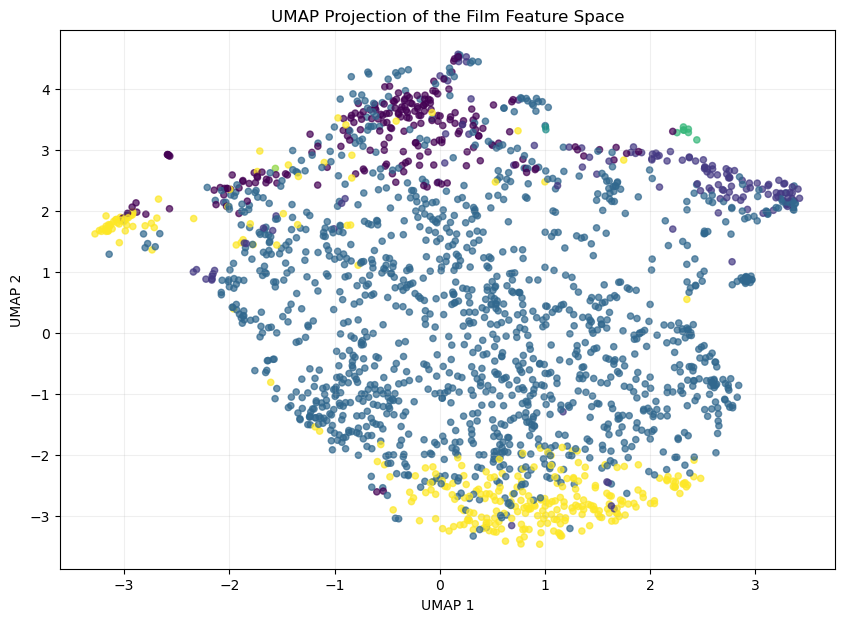

In [24]:
plt.figure(figsize=(10, 7))

plt.scatter(
    umap_df["x"],
    umap_df["y"],
    c=umap_df["cluster"],
    s=20,
    alpha=0.7
)

plt.title("UMAP Projection of the Film Feature Space")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.grid(alpha=0.2)
plt.show()

In [25]:
umap_projection_path = RESULTS_DIR / "umap_projection.csv"
umap_df.to_csv(umap_projection_path, index=False)

print("Saved UMAP projection to:", umap_projection_path)

Saved UMAP projection to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results\umap_projection.csv


In [26]:
umap_model = umap.UMAP(
    n_neighbors=30,
    min_dist=0.10,
    n_components=2,
    metric="cosine",
    random_state=42,
    low_memory=True
)

## 9. Visualize the film space in 2D

For a simple baseline view, we project the sparse feature space into two dimensions.

Since the feature matrix is sparse, we use TruncatedSVD as a practical PCA-style approximation.

In [27]:
svd_2d = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd_2d.fit_transform(X_model)

plot_df = pd.DataFrame({
    "x": X_2d[:, 0],
    "y": X_2d[:, 1],
    "cluster": cluster_labels,
    "title": df[display_col].astype(str)
})

plot_df.head()

,x,y,cluster,title
0,0.868361,0.649615,6,"Poland, 1962. Anna, an orphan brought up by nu..."
1,0.163659,0.044702,2,Loosely-based on the true events of a homeless...
2,1.328451,0.971941,6,"Louis, a young teacher enamored of the age of ..."
3,0.232114,-0.151810,2,"An outlandish science-fiction, comedy-thriller..."
4,0.637058,0.515786,2,"Mrs. Palfrey (Dame Joan Plowright), recently w..."


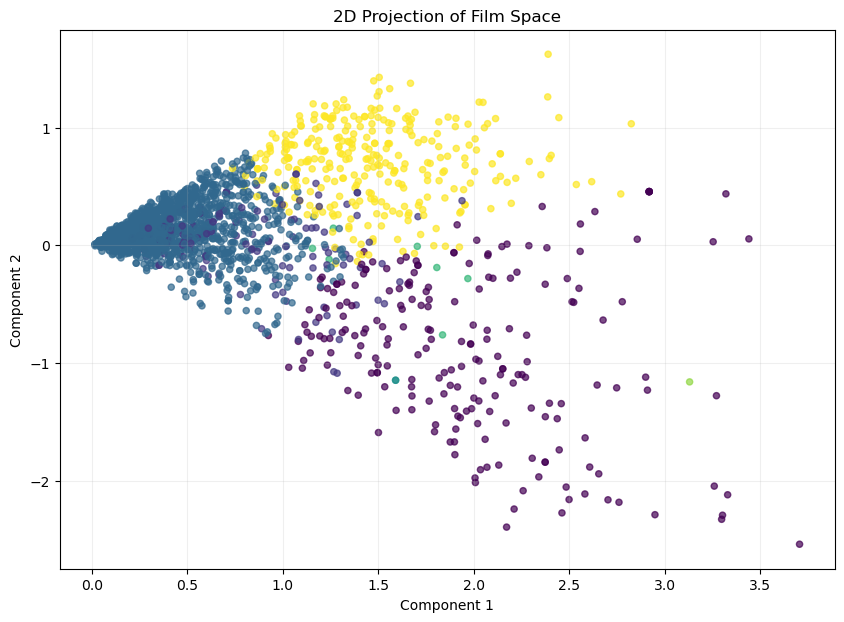

In [28]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    plot_df["x"],
    plot_df["y"],
    c=plot_df["cluster"],
    s=20,
    alpha=0.7
)

plt.title("2D Projection of Film Space")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.grid(alpha=0.2)
plt.show()

In [29]:
representative_indices_all = []

for cluster_id in sorted(df["cluster"].unique()):
    reps = get_representative_films(
        matrix=X_model,
        model=kmeans_model,
        labels=cluster_labels,
        cluster_id=cluster_id,
        df=df,
        title_col=display_col,
        top_n=2
    )
    representative_indices_all.extend(reps.index.tolist())

representative_indices_all = sorted(set(representative_indices_all))

## 10. Save clustering outputs

We save the final clustering assignments and the cluster profile table for later analysis and reporting.

In [30]:
clustered_films_path = RESULTS_DIR / "clustered_films.csv"
cluster_profiles_path = RESULTS_DIR / "cluster_profiles.csv"
evaluation_plot_only_path = RESULTS_DIR / "evaluation_plot_only.csv"
evaluation_weighted_path = RESULTS_DIR / "evaluation_weighted.csv"

df.to_csv(clustered_films_path, index=False)
cluster_profiles_df.to_csv(cluster_profiles_path, index=False)
evaluation_plot_only.to_csv(evaluation_plot_only_path, index=False)
evaluation_weighted.to_csv(evaluation_weighted_path, index=False)

print("Saved clustered films to:", clustered_films_path)
print("Saved cluster profiles to:", cluster_profiles_path)
print("Saved evaluation tables to:", RESULTS_DIR)

Saved clustered films to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results\clustered_films.csv
Saved cluster profiles to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results\cluster_profiles.csv
Saved evaluation tables to: c:\Users\Georg\Desktop\DTU\FATA\FataProject\outputs\text_clustering\results


## Output of this notebook

At the end of this notebook, we have:

- similarity exploration
- clustering results for selected values of k
- a final clustering solution
- interpretable cluster profiles
- a 2D visualization of the dataset

The next stage can extend this analysis with:
- Oscar recognition patterns by cluster
- IMDb rating and popularity comparisons
- positioning of new film loglines in the same feature space